In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
SEED = 42

df = pd.read_csv('../data/spreadspoke_scores.csv')

# filtrem empats (poc freqüents a la NFL) per tenir classificació binària neta
df = df[df['score_home'] != df['score_away']].copy()

# creem el Target: 1 si guanya l'equip local, 0 si guanya el visitant
df['home_win'] = (df['score_home'] > df['score_away']).astype(int)

# eliminem columnes del futur (puntuacions finals) per evitar filtració d'informació
cols_future = ['score_home', 'score_away', 'overtime']
df = df.drop(columns=[c for c in cols_future if c in df.columns])

# partitioning TEMPORAL (Train: <= 2020, Test: > 2020)
# Aquest pas es fa ABANS de calcular cap mitjana, valor perdut o correlació per evitar Data Leakage
train_mask = df['schedule_season'] <= 2020
test_mask = df['schedule_season'] > 2020

df_train = df[train_mask].copy()
df_test = df[test_mask].copy()

X_train = df_train.drop(columns=['home_win'])
y_train = df_train['home_win']

X_test = df_test.drop(columns=['home_win'])
y_test = df_test['home_win']

print(f"Dataset total processat: {df.shape[0]} partits")
print(f"Conjunt d'entrenament (X_train - fins 2020): {X_train.shape[0]} partits")
print(f"Conjunt de test reservat (X_test - 2021+): {X_test.shape[0]} partits")

Dataset total processat: 14279 partits
Conjunt d'entrenament (X_train - fins 2020): 12859 partits
Conjunt de test reservat (X_test - 2021+): 1420 partits


C:\Users\roces\AppData\Local\Temp\ipykernel_876\43560065.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y_train, palette='Set2')


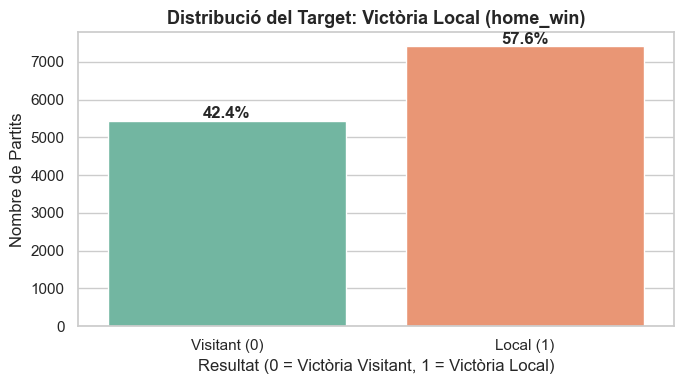

--- Valors Perduts al conjunt d'entrenament ---
                     Absoluts  Percentatge (%)
weather_detail          10065        78.272027
weather_humidity         4501        35.002722
over_under_line          2400        18.663971
weather_wind_mph          856         6.656816
weather_temperature       839         6.524613
team_favorite_id            5         0.038883
spread_favorite             5         0.038883


In [2]:
# DISTRIBUCIÓ DEL TARGET 
plt.figure(figsize=(7, 4))
ax = sns.countplot(x=y_train, palette='Set2')
plt.title("Distribució del Target: Victòria Local (home_win)", fontsize=13, fontweight='bold')
plt.xlabel("Resultat (0 = Victòria Visitant, 1 = Victòria Local)")
plt.ylabel("Nombre de Partits")
plt.xticks([0, 1], ['Visitant (0)', 'Local (1)'])

# afegim percentatges a sobre de les barres
total = len(y_train)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

# ANÀLISI DE VALORS PERDUTS AL TRAIN 
missing_vals = X_train.isnull().sum()
missing_perc = (missing_vals / len(X_train)) * 100
df_missing = pd.DataFrame({'Absoluts': missing_vals, 'Percentatge (%)': missing_perc})
df_missing = df_missing[df_missing['Absoluts'] > 0].sort_values(by='Percentatge (%)', ascending=False)

print("--- Valors Perduts al conjunt d'entrenament ---")
print(df_missing)